# Spinup drift check — full 22-year run
Covers: (1) domain-mean water-year drift for 8 fields, (2) site-level check at Florida wetland / Yuma / WA Pacific NW using the P/storage ratio extremes, (3) numeric drift summaries for both.

## 1. Setup

In [1]:
import glob
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# casename="irrigation_on"
# casename="control"
# casename="evolving_landcover"
casename="hillslope_on"


HIST_DIR = f"/glade/derecho/scratch/mozhgana/archive/{casename}/lnd/hist/"
MONTHLY_PATTERN = f"{casename}.clm2.h0a.*.nc"
DAILY_PATTERN = f"{casename}.clm2.h1a.*.nc"

DOMAIN_FIELDS = [
    "TOTSOILLIQ", "TOTSOILICE", "ZWT", "H2OSNO",
    "TWS", "FSH", "EFLX_LH_TOT", "TSOI",
]

SITE_FIELDS = ["TOTSOILLIQ", "TOTSOILICE", "ZWT", "TSOI", "RAIN", "SNOW"]


# Sites derived from the P/storage ratio calc (lowest & highest in our own
# domain), plus Yuma as a general arid-Southwest reference.
KNOWN_SITES = {
    (25.0625, 283.9375): "S. Florida wetland (lowest P/storage ratio)",
    (32.7, 245.4): "Yuma, AZ area (arid Southwest reference)",
    (47.8125, 236.0625): "WA Pacific NW (highest P/storage ratio)",
}

def label_for(lat, lon, tol=0.3):
    for (slat, slon), name in KNOWN_SITES.items():
        if abs(lat - slat) < tol and abs(lon - slon) < tol:
            return name
    return "unlabeled site"

## 2. Domain-mean water-year check (monthly h0a, all 22 years)

In [2]:
files_monthly = sorted(glob.glob(HIST_DIR + MONTHLY_PATTERN))
print(f"Found {len(files_monthly)} monthly files")
print(files_monthly[0], "...", files_monthly[-1])

def _keep_domain_fields(ds):
    keep = [f for f in DOMAIN_FIELDS if f in ds.variables]
    return ds[keep]

ds_monthly = xr.open_mfdataset(
    files_monthly,
    combine="nested",
    concat_dim="time",
    decode_times=True,
    parallel=True,
    preprocess=_keep_domain_fields,
)
ds_monthly

Found 288 monthly files
/glade/derecho/scratch/mozhgana/archive/hillslope_on/lnd/hist/hillslope_on.clm2.h0a.1980-10.nc ... /glade/derecho/scratch/mozhgana/archive/hillslope_on/lnd/hist/hillslope_on.clm2.h0a.2004-09.nc


<xarray.Dataset> Size: 4GB
Dimensions:      (time: 288, lat: 224, lon: 464, levgrnd: 25)
Coordinates:
  * time         (time) object 2kB 1980-10-16 12:00:00 ... 2004-09-16 00:00:00
  * lat          (lat) float32 896B 25.06 25.19 25.31 ... 52.69 52.81 52.94
  * lon          (lon) float32 2kB 235.1 235.2 235.3 235.4 ... 292.7 292.8 292.9
  * levgrnd      (levgrnd) float32 100B 0.01 0.04 0.09 0.16 ... 19.48 28.87 42.0
Data variables:
    TOTSOILLIQ   (time, lat, lon) float32 120MB dask.array<chunksize=(1, 224, 464), meta=np.ndarray>
    TOTSOILICE   (time, lat, lon) float32 120MB dask.array<chunksize=(1, 224, 464), meta=np.ndarray>
    ZWT          (time, lat, lon) float32 120MB dask.array<chunksize=(1, 224, 464), meta=np.ndarray>
    H2OSNO       (time, lat, lon) float32 120MB dask.array<chunksize=(1, 224, 464), meta=np.ndarray>
    TWS          (time, lat, lon) float32 120MB dask.array<chunksize=(1, 224, 464), meta=np.ndarray>
    FSH          (time, lat, lon) float32 120MB dask.array<chunksize=(1, 224, 464), meta=np.ndarray>
    EFLX_LH_TOT  (time, lat, lon) float32 120MB dask.array<chunksize=(1, 224, 464), meta=np.ndarray>
    TSOI         (time, levgrnd, lat, lon) float32 3GB dask.array<chunksize=(1, 25, 224, 464), meta=np.ndarray>
Attributes: (12/100)
    title:                                CLM History file information
    comment:                              NOTE: None of the variables are wei...
    Conventions:                          CF-1.0
    history:                              created on 09/11/26 03:23:40
    source:                               Community Terrestrial Systems Model
    hostname:                             derecho
    ...                                   ...
    cft_irrigated_switchgrass:            60
    cft_tropical_corn:                    61
    cft_irrigated_tropical_corn:          62
    cft_tropical_soybean:                 63
    cft_irrigated_tropical_soybean:       64
    time_period_freq:                     month_1

In [3]:
# Assign water-year coordinate, keep only full (12-month) water years
def water_year_labels(time_da):
    months = time_da.dt.month.values
    years = time_da.dt.year.values
    return np.where(months >= 10, years + 1, years)

wy = water_year_labels(ds_monthly["time"])
ds_monthly = ds_monthly.assign_coords(water_year=("time", wy))

months_per_wy = ds_monthly["time"].groupby("water_year").count()
full_water_years = months_per_wy.where(months_per_wy == 12, drop=True)["water_year"].values
print("Full (12-month) water years:", full_water_years)

Full (12-month) water years: [1981 1982 1983 1984 1985 1986 1987 1988 1989 1990 1991 1992 1993 1994
 1995 1996 1997 1998 1999 2000 2001 2002 2003 2004]


In [4]:
domain_mean_wy = {}
for f in DOMAIN_FIELDS:
    if f not in ds_monthly:
        print(f"WARNING: {f} not found, skipping.")
        continue
    spatial_dims = [d for d in ds_monthly[f].dims if d not in ("time",)]
    da = ds_monthly[f].mean(dim=spatial_dims, skipna=True)
    grouped = da.groupby("water_year").mean().load()
    grouped = grouped.where(grouped["water_year"].isin(full_water_years), drop=True)
    domain_mean_wy[f] = grouped

list(domain_mean_wy.keys())

['TOTSOILLIQ',
 'TOTSOILICE',
 'ZWT',
 'H2OSNO',
 'TWS',
 'FSH',
 'EFLX_LH_TOT',
 'TSOI']

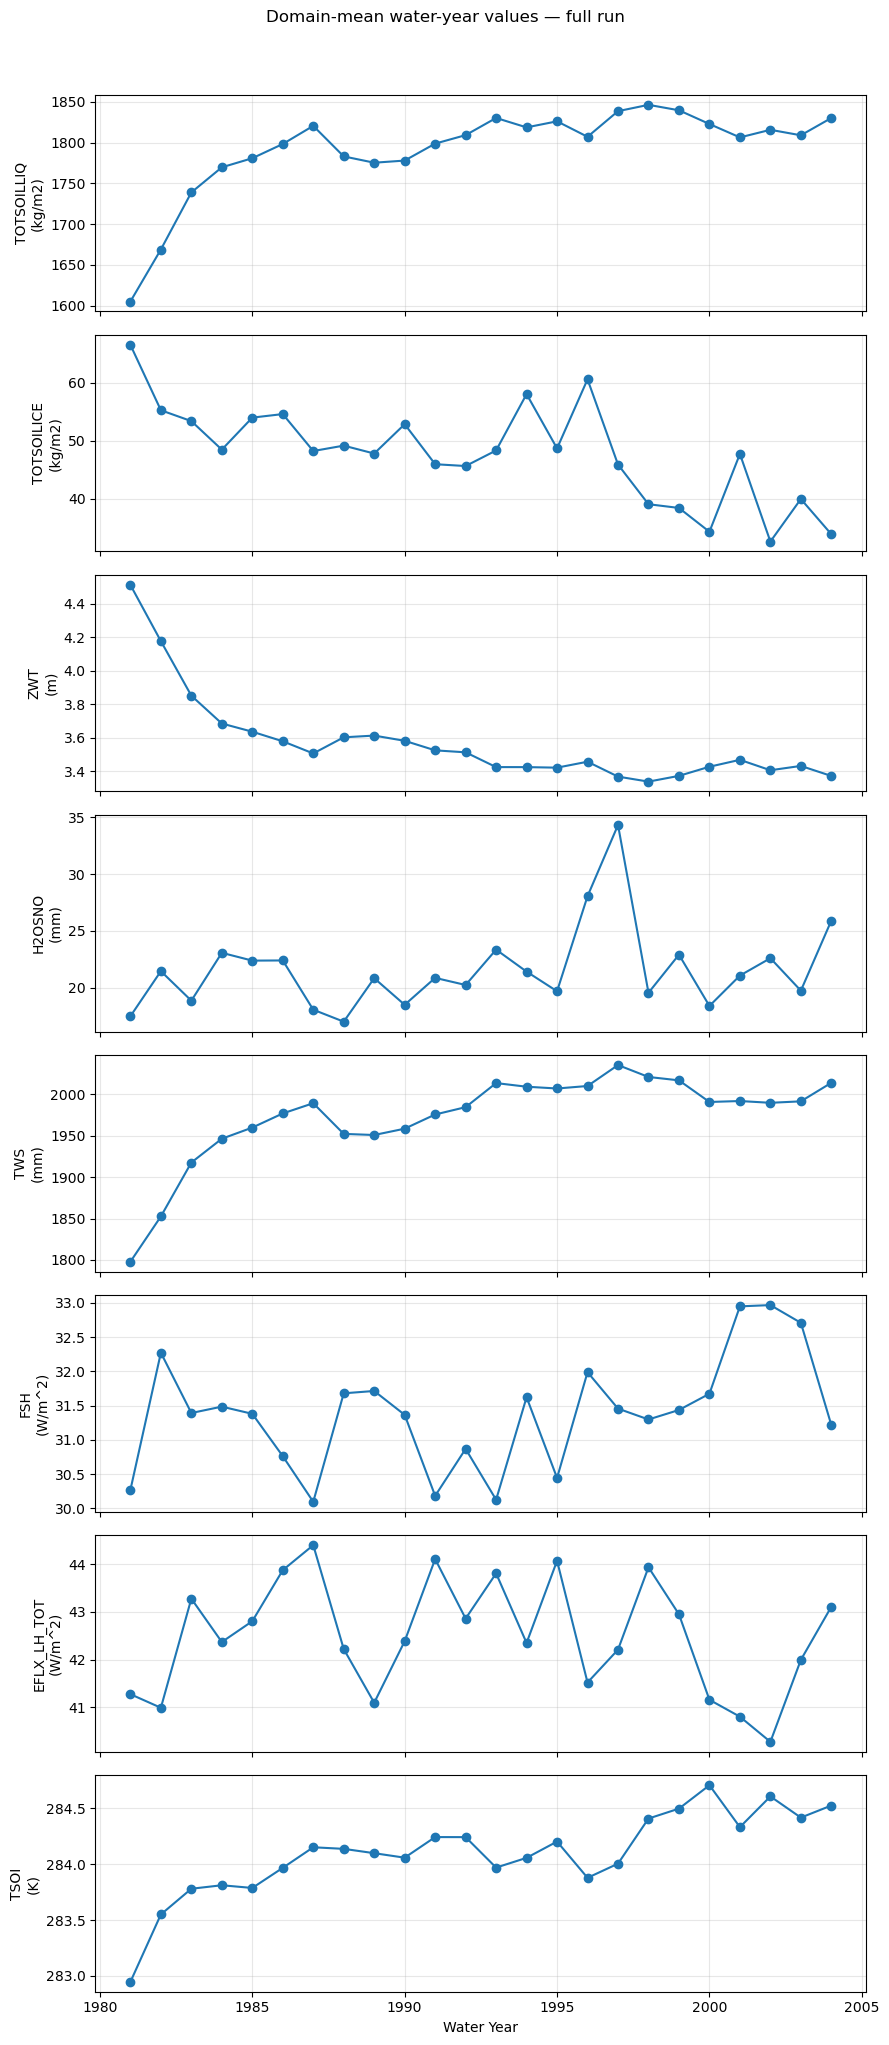

In [5]:
n = len(domain_mean_wy)
fig, axes = plt.subplots(n, 1, figsize=(9, 2.5 * n), sharex=True)
if n == 1:
    axes = [axes]

for ax, (fname, da) in zip(axes, domain_mean_wy.items()):
    ax.plot(da["water_year"].values, da.values, marker="o")
    units = ds_monthly[fname].attrs.get("units", "")
    ax.set_ylabel(f"{fname}\n({units})")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Water Year")
fig.suptitle("Domain-mean water-year values — full run", y=1.02)
fig.tight_layout()
plt.show()

In [6]:
print("--- Domain-mean drift summary (last 2 WY mean vs previous 2 WY mean) ---")
for fname, da in domain_mean_wy.items():
    if len(da) >= 4:
        recent = da.isel(water_year=slice(-2, None)).mean().values
        prior = da.isel(water_year=slice(-4, -2)).mean().values
        pct_change = 100 * (recent - prior) / prior if prior != 0 else np.nan
        print(f"{fname}: prior={prior:.4f}, recent={recent:.4f}, change={pct_change:.2f}%")
    else:
        print(f"{fname}: not enough water years to compare")

--- Domain-mean drift summary (last 2 WY mean vs previous 2 WY mean) ---
TOTSOILLIQ: prior=1811.0325, recent=1819.5852, change=0.47%
TOTSOILICE: prior=40.1779, recent=36.9236, change=-8.10%
ZWT: prior=3.4371, recent=3.4018, change=-1.03%
H2OSNO: prior=21.8198, recent=22.8131, change=4.55%
TWS: prior=1990.6864, recent=2002.5786, change=0.60%
FSH: prior=32.9561, recent=31.9616, change=-3.02%
EFLX_LH_TOT: prior=40.5349, recent=42.5509, change=4.97%
TSOI: prior=284.4678, recent=284.4697, change=0.00%


## 3. Site-level check (daily h1a, all 22 years) — Florida / Yuma / WA

In [7]:
files_daily = sorted(glob.glob(HIST_DIR + DAILY_PATTERN))
print(f"Found {len(files_daily)} daily files")

def _keep_site_fields(ds):
    keep = [f for f in SITE_FIELDS if f in ds.variables]
    return ds[keep]

ds_daily = xr.open_mfdataset(
    files_daily,
    combine="nested",
    concat_dim="time",
    decode_times=True,
    parallel=True,
    preprocess=_keep_site_fields,
)
ds_daily

Found 24 daily files


<xarray.Dataset> Size: 109GB
Dimensions:     (time: 8760, lat: 224, lon: 464, levgrnd: 25)
Coordinates:
  * time        (time) object 70kB 1980-10-01 12:00:00 ... 2004-09-30 12:00:00
  * lat         (lat) float32 896B 25.06 25.19 25.31 25.44 ... 52.69 52.81 52.94
  * lon         (lon) float32 2kB 235.1 235.2 235.3 235.4 ... 292.7 292.8 292.9
  * levgrnd     (levgrnd) float32 100B 0.01 0.04 0.09 0.16 ... 19.48 28.87 42.0
Data variables:
    TOTSOILLIQ  (time, lat, lon) float32 4GB dask.array<chunksize=(365, 224, 464), meta=np.ndarray>
    TOTSOILICE  (time, lat, lon) float32 4GB dask.array<chunksize=(365, 224, 464), meta=np.ndarray>
    ZWT         (time, lat, lon) float32 4GB dask.array<chunksize=(365, 224, 464), meta=np.ndarray>
    TSOI        (time, levgrnd, lat, lon) float32 91GB dask.array<chunksize=(365, 25, 224, 464), meta=np.ndarray>
    RAIN        (time, lat, lon) float32 4GB dask.array<chunksize=(365, 224, 464), meta=np.ndarray>
    SNOW        (time, lat, lon) float32 4GB dask.array<chunksize=(365, 224, 464), meta=np.ndarray>
Attributes: (12/100)
    title:                                CLM History file information
    comment:                              NOTE: None of the variables are wei...
    Conventions:                          CF-1.0
    history:                              created on 09/11/26 03:18:23
    source:                               Community Terrestrial Systems Model
    hostname:                             derecho
    ...                                   ...
    cft_irrigated_switchgrass:            60
    cft_tropical_corn:                    61
    cft_irrigated_tropical_corn:          62
    cft_tropical_soybean:                 63
    cft_irrigated_tropical_soybean:       64
    time_period_freq:                     day_1

In [ ]:
lats = [lat for (lat, lon) in KNOWN_SITES.keys()]
lons = [lon for (lat, lon) in KNOWN_SITES.keys()]
names = list(KNOWN_SITES.values())

# One combined selection across all sites at once
points = ds_daily.sel(
    lat=xr.DataArray(lats, dims="site"),
    lon=xr.DataArray(lons, dims="site"),
    method="nearest"
).load()  # single read instead of 3 separate .load() calls

# Split back into a per-site dict, same structure as before
site_data = {}
for i, name in enumerate(names):
    site_point = points.isel(site=i)
    site_data[name] = site_point
    actual_lat = float(site_point["lat"].values)
    actual_lon = float(site_point["lon"].values)
    requested_lat, requested_lon = lats[i], lons[i]
    print(f"{name}: requested ({requested_lat}, {requested_lon}), nearest grid cell ({actual_lat:.3f}, {actual_lon:.3f})")

In [ ]:
# TSOI has a levgrnd dimension -- use a deep layer (index 15) for the site plots,
# consistent with earlier analysis.
DEEP_LAYER_IDX = 15

def get_plot_series(ds_site, field):
    da = ds_site[field]
    if "levgrnd" in da.dims:
        da = da.isel(levgrnd=DEEP_LAYER_IDX)
    time_vals = np.array(
        [t.strftime("%Y-%m-%d") for t in ds_site["time"].values], dtype="datetime64[D]"
    )
    return time_vals, da.values

fig, axes = plt.subplots(len(SITE_FIELDS), 1, figsize=(11, 3 * len(SITE_FIELDS)), sharex=True)
for ax, field in zip(axes, SITE_FIELDS):
    for name, ds_site in site_data.items():
        if field in ds_site:
            x, y = get_plot_series(ds_site, field)
            ax.plot(x, y, label=name, linewidth=0.8, alpha=0.85)
    ax.set_ylabel(field)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")
fig.suptitle("Site-level daily series — full 22-year run", y=1.01)
fig.tight_layout()
plt.show()

In [ ]:
# Annual means per site -- easier to read drift than noisy daily data
annual_by_site = {}
for field in SITE_FIELDS:
    print(f"\n--- {field} annual means ---")
    annual_by_site[field] = {}
    for name, ds_site in site_data.items():
        if field not in ds_site:
            continue
        da = ds_site[field]
        if "levgrnd" in da.dims:
            da = da.isel(levgrnd=DEEP_LAYER_IDX)
        annual = da.resample(time="YS").mean()
        annual_by_site[field][name] = annual
        print(f"{name}:")
        for t, v in zip(annual["time"].dt.year.values, annual.values):
            print(f"  {t}: {v:.3f}")

In [ ]:
# Numeric drift summary per site: last 2 years vs previous 2 years
print("--- Site-level drift summary (last 2yr mean vs previous 2yr mean) ---")
for field in SITE_FIELDS:
    print(f"\n{field}:")
    for name, annual in annual_by_site[field].items():
        if len(annual) >= 4:
            recent = annual.isel(time=slice(-2, None)).mean().values
            prior = annual.isel(time=slice(-4, -2)).mean().values
            pct_change = 100 * (recent - prior) / prior if prior != 0 else np.nan
            print(f"  {name}: prior={prior:.4f}, recent={recent:.4f}, change={pct_change:.2f}%")
        else:
            print(f"  {name}: not enough years to compare")

## 4. Interactive point check (optional, exploratory)

In [40]:
import ipywidgets as widgets

def plot_at_point(lat, lon, field):
    point = ds_daily.sel(lat=lat, lon=lon, method="nearest")
    actual_lat = float(point["lat"].values)
    actual_lon = float(point["lon"].values)
    loc_name = label_for(actual_lat, actual_lon)

    fig, ax = plt.subplots(figsize=(10, 3))
    x, y = get_plot_series(point, field)
    ax.plot(x, y)
    ax.set_title(f"{field} near {loc_name}  (grid cell: {actual_lat:.3f}, {actual_lon:.3f})")
    ax.grid(alpha=0.3)
    plt.show()

widgets.interact(
    plot_at_point,
    lat=widgets.FloatSlider(min=25, max=53, step=0.125, value=32.7, description="lat"),
    lon=widgets.FloatSlider(min=235, max=293, step=0.125, value=245.4, description="lon"),
    field=widgets.Dropdown(options=SITE_FIELDS),
)

interactive(children=(FloatSlider(value=32.7, description='lat', max=53.0, min=25.0, step=0.125), FloatSlider(…

<function __main__.plot_at_point(lat, lon, field)>

In [ ]:
# KNOWN_SITES = {
#     (25.0625, 283.9375): "S. Florida wetland (lowest P/storage ratio)",
#     (32.7, 245.4): "Yuma, AZ area (arid Southwest reference)",
#     (47.8125, 236.0625): "WA Pacific NW (highest P/storage ratio)",
# }

Nearest grid cell: (25.062, 283.938)
Saved florida_soilliq_vs_precip.png


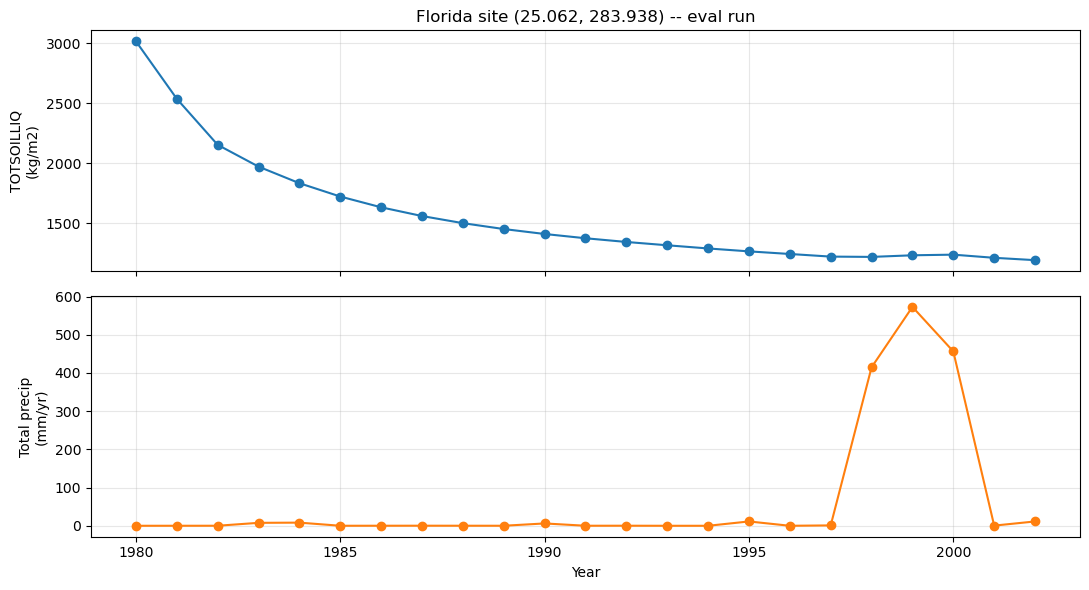


Correlation between annual TOTSOILLIQ and annual total precip: -0.281
(High positive correlation supports 'real climate signal';
 low/no correlation supports 'model adjustment artifact')


In [41]:
"""
Check: does the Florida site's TOTSOILLIQ decline (1980-2010) then recovery
(2010-2018) pattern in the eval run match real precipitation variability,
or does it look like a model-adjustment artifact from replaying the
spinup-period forcing?

Run this in the same notebook/session where `ds_daily`is
already loaded.
"""

import glob
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt




FLORIDA_LAT = 25.0625
FLORIDA_LON = 283.9375



# Check RAIN/SNOW are actually in this history stream -- if not, need to add
# them to hist_fincl before this check is possible, or pull from a stream
# that does have them.
missing = [f for f in SITE_FIELDS if f not in ds_daily]
if missing:
    print(f"WARNING: {missing} not found in this history stream.")
    print("Available fields:", list(ds.data_vars))

point = ds_daily.sel(lat=FLORIDA_LAT, lon=FLORIDA_LON, method="nearest")
actual_lat = float(point["lat"].values)
actual_lon = float(point["lon"].values)
print(f"Nearest grid cell: ({actual_lat:.3f}, {actual_lon:.3f})")

point = point.load()

# Annual means: TOTSOILLIQ, and total precip (RAIN+SNOW) if available
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

soilliq_annual = point["TOTSOILLIQ"].resample(time="YS").mean()
axes[0].plot(soilliq_annual["time"].dt.year.values, soilliq_annual.values, marker="o")
axes[0].set_ylabel("TOTSOILLIQ\n(kg/m2)")
axes[0].grid(alpha=0.3)
axes[0].set_title(f"Florida site ({actual_lat:.3f}, {actual_lon:.3f}) -- eval run")

if "RAIN" in point and "SNOW" in point:
    precip = point["RAIN"] + point["SNOW"]
    # RAIN/SNOW are rates (mm/s) -- convert to annual total (mm/yr) for a
    # meaningful comparison, not just annual mean rate
    seconds_per_day = 86400
    precip_daily_mm = precip * seconds_per_day
    precip_annual_total = precip_daily_mm.resample(time="YS").sum()
    axes[1].plot(precip_annual_total["time"].dt.year.values,
                 precip_annual_total.values, marker="o", color="tab:orange")
    axes[1].set_ylabel("Total precip\n(mm/yr)")
    axes[1].grid(alpha=0.3)
else:
    axes[1].text(0.5, 0.5, "RAIN/SNOW not in this history stream\n(add to hist_fincl to check)",
                 ha="center", va="center", transform=axes[1].transAxes)

axes[1].set_xlabel("Year")
plt.tight_layout()
# plt.savefig("florida_soilliq_vs_precip.png", dpi=150, bbox_inches="tight")
print("Saved florida_soilliq_vs_precip.png")
plt.show()

# Numeric correlation check (only meaningful if both series available)
if "RAIN" in point and "SNOW" in point:
    # Align lengths in case of any mismatch
    n = min(len(soilliq_annual), len(precip_annual_total))
    corr = np.corrcoef(soilliq_annual.values[:n], precip_annual_total.values[:n])[0, 1]
    print(f"\nCorrelation between annual TOTSOILLIQ and annual total precip: {corr:.3f}")
    print("(High positive correlation supports 'real climate signal';")
    print(" low/no correlation supports 'model adjustment artifact')")

In [42]:
import numpy as np

ds_forcing = xr.open_dataset(
    "/glade/campaign/cesm/cesmdata/inputdata/atm/datm7/atm_forcing.datm7.NLDAS2.0.125d.v1/Precip/ctsmforc.NLDAS2.0.125d.v1.Prec.1985-06.nc"
)

# LATIXY/LONGXY are 2D (lat, lon) arrays giving the real coordinate at each index
lat_2d = ds_forcing["LATIXY"].values
lon_2d = ds_forcing["LONGXY"].values

# Find the index closest to our Florida site
target_lat, target_lon = 25.0625, 283.9375
dist = (lat_2d - target_lat)**2 + (lon_2d - target_lon)**2
lat_idx, lon_idx = np.unravel_index(np.argmin(dist), dist.shape)

print(f"Nearest index: lat_idx={lat_idx}, lon_idx={lon_idx}")
print(f"Actual coords at that index: lat={lat_2d[lat_idx, lon_idx]:.3f}, lon={lon_2d[lat_idx, lon_idx]:.3f}")

# Now extract precipitation at that index using isel (position-based), not sel
point = ds_forcing["PRECTmms"].isel(lat=lat_idx, lon=lon_idx)
print("Min:", point.min().values)
print("Max:", point.max().values)
print("Mean:", point.mean().values)
print("First 20 values:", point.values[:20])

Nearest index: lat_idx=0, lon_idx=391
Actual coords at that index: lat=25.062, lon=283.938
Min: 0.0
Max: 3.33333360913457e-07
Mean: 1.813271532924432e-09
First 20 values: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [43]:
# Try lat_idx a bit higher (further from the boundary), same lon area
point_interior = ds_forcing["PRECTmms"].isel(lat=lat_idx+10, lon=lon_idx)
print("Mean:", point_interior.mean().values)


Mean: nan


In [44]:
# Check the actual lat/lon more precisely, and look at neighboring cells
# systematically to map out what's land vs water vs "weird" near your point
for dlat in [-2, -1, 0, 1, 2]:
    for dlon in [-2, -1, 0, 1, 2]:
        try:
            p = ds_forcing["PRECTmms"].isel(lat=lat_idx+dlat, lon=lon_idx+dlon)
            m = float(p.mean().values)
            print(f"dlat={dlat}, dlon={dlon}: mean={m:.6e}")
        except IndexError:
            print(f"dlat={dlat}, dlon={dlon}: out of bounds")

dlat=-2, dlon=-2: mean=2.732922e-05
dlat=-2, dlon=-1: mean=2.776482e-05
dlat=-2, dlon=0: mean=2.819815e-05
dlat=-2, dlon=1: mean=2.848298e-05
dlat=-2, dlon=2: mean=2.850680e-05
dlat=-1, dlon=-2: mean=2.717619e-05
dlat=-1, dlon=-1: mean=2.748360e-05
dlat=-1, dlon=0: mean=2.777583e-05
dlat=-1, dlon=1: mean=2.807147e-05
dlat=-1, dlon=2: mean=2.822570e-05
dlat=0, dlon=-2: mean=nan
dlat=0, dlon=-1: mean=4.552470e-09
dlat=0, dlon=0: mean=1.813272e-09
dlat=0, dlon=1: mean=nan
dlat=0, dlon=2: mean=nan
dlat=1, dlon=-2: mean=2.214506e-08
dlat=1, dlon=-1: mean=1.346451e-08
dlat=1, dlon=0: mean=nan
dlat=1, dlon=1: mean=nan
dlat=1, dlon=2: mean=nan
dlat=2, dlon=-2: mean=3.703704e-08
dlat=2, dlon=-1: mean=nan
dlat=2, dlon=0: mean=nan
dlat=2, dlon=1: mean=nan
dlat=2, dlon=2: mean=nan


Candidate site nearest index: lat_idx=43, lon_idx=267
Actual coords: lat=30.438, lon=268.438
(lat_idx away from edges: 43 from south, 180 from north)

June 1985 PRECTmms at candidate site: mean=3.2340e-05, max=2.6917e-03
>>> Forcing data looks like real precipitation. Proceeding to Step 2. <<<

Found 22 eval-run daily files
Eval-run nearest grid cell: (30.562, 268.562)
Saved interior_wetland_soilliq_check.png


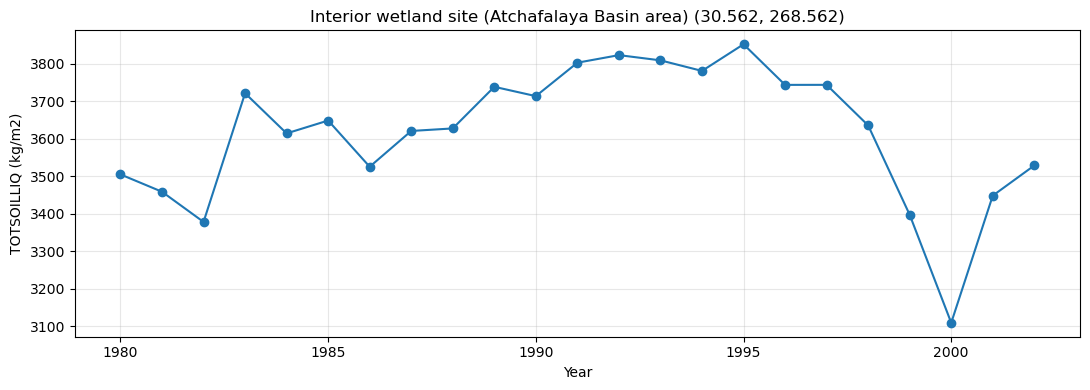


Drift check: prior=3253.29, recent=3488.67, change=7.24%


In [45]:
"""
Re-check spinup/equilibration at a genuine interior high-storage wetland site,
avoiding the domain-edge artifact found at the original "Florida" site
(lat_idx=0, isolated near-zero-precip coastal fragment).

Candidate: Atchafalaya Basin, Louisiana -- a large interior river-swamp/wetland
system, well away from any domain edge (~30.5N, -91.5W / 268.5E), unlike the
original site which sat at the very southern boundary row of the grid.

Step 1: verify forcing data at this site is valid (not near-zero, not NaN)
        -- do this FIRST, learned from the mistake with the Florida site.
Step 2: only if forcing looks real, check TOTSOILLIQ trend over the full
        38-year eval run to assess whether spinup was adequate there.
"""

import glob
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# STEP 1: Verify forcing data validity at the candidate site
# ---------------------------------------------------------------------------
FORCING_FILE = "/glade/campaign/cesm/cesmdata/inputdata/atm/datm7/atm_forcing.datm7.NLDAS2.0.125d.v1/Precip/ctsmforc.NLDAS2.0.125d.v1.Prec.1985-06.nc"

CANDIDATE_LAT = 30.5
CANDIDATE_LON = 268.5  # -91.5 + 360

ds_forcing = xr.open_dataset(FORCING_FILE)
lat_2d = ds_forcing["LATIXY"].values
lon_2d = ds_forcing["LONGXY"].values

dist = (lat_2d - CANDIDATE_LAT) ** 2 + (lon_2d - CANDIDATE_LON) ** 2
lat_idx, lon_idx = np.unravel_index(np.argmin(dist), dist.shape)

print(f"Candidate site nearest index: lat_idx={lat_idx}, lon_idx={lon_idx}")
print(f"Actual coords: lat={lat_2d[lat_idx, lon_idx]:.3f}, lon={lon_2d[lat_idx, lon_idx]:.3f}")
print(f"(lat_idx away from edges: {lat_idx} from south, {lat_2d.shape[0]-1-lat_idx} from north)")

point_forcing = ds_forcing["PRECTmms"].isel(lat=lat_idx, lon=lon_idx)
mean_val = float(point_forcing.mean().values)
max_val = float(point_forcing.max().values)
print(f"\nJune 1985 PRECTmms at candidate site: mean={mean_val:.4e}, max={max_val:.4e}")

# Sanity threshold: real precip events should show max values several
# orders of magnitude above the ~1e-9 "near-zero artifact" seen at the
# broken Florida site. A reasonable rain event is ~1e-4 to 1e-3 mm/s-ish.
if np.isnan(mean_val):
    print("*** WARNING: NaN -- this cell is masked/ocean, pick a different site ***")
elif mean_val < 1e-7:
    print("*** WARNING: still looks like the same near-zero artifact -- pick a different site ***")
else:
    print(">>> Forcing data looks like real precipitation. Proceeding to Step 2. <<<")

# ---------------------------------------------------------------------------
# STEP 2: Check TOTSOILLIQ trend at this site over the full 38-year eval run
# ---------------------------------------------------------------------------
HIST_DIR = f"/glade/derecho/scratch/mozhgana/archive/{casename}/lnd/hist/"
FILE_PATTERN = f"{casename}.clm2.h1a.*-10-02-00000.nc"

files = sorted(glob.glob(HIST_DIR + FILE_PATTERN))
print(f"\nFound {len(files)} eval-run daily files")

def _keep_fields(ds):
    keep = [f for f in ["TOTSOILLIQ"] if f in ds.variables]
    return ds[keep]

ds_eval = xr.open_mfdataset(
    files, combine="nested", concat_dim="time",
    decode_times=True, parallel=True, preprocess=_keep_fields,
)

point_eval = ds_eval["TOTSOILLIQ"].sel(
    lat=CANDIDATE_LAT, lon=CANDIDATE_LON, method="nearest"
).load()
actual_lat = float(point_eval["lat"].values)
actual_lon = float(point_eval["lon"].values)
print(f"Eval-run nearest grid cell: ({actual_lat:.3f}, {actual_lon:.3f})")

annual = point_eval.resample(time="YS").mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(annual["time"].dt.year.values, annual.values, marker="o")
ax.set_ylabel("TOTSOILLIQ (kg/m2)")
ax.set_xlabel("Year")
ax.set_title(f"Interior wetland site (Atchafalaya Basin area) ({actual_lat:.3f}, {actual_lon:.3f})")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("interior_wetland_soilliq_check.png", dpi=150, bbox_inches="tight")
print("Saved interior_wetland_soilliq_check.png")
plt.show()

# Numeric drift check: last 2yr vs previous 2yr, same convention as before
if len(annual) >= 4:
    recent = annual.isel(time=slice(-2, None)).mean().values
    prior = annual.isel(time=slice(-4, -2)).mean().values
    pct_change = 100 * (recent - prior) / prior if prior != 0 else np.nan
    print(f"\nDrift check: prior={prior:.2f}, recent={recent:.2f}, change={pct_change:.2f}%")